In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [4]:
df = pd.read_csv("../data/telco_churn.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.describe(include="all"))
print(df.isnull().sum())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [6]:
# Clean the common TotalCharges formatting issue:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

In [7]:
# Convert the target:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [9]:
# Remove rows with a missing target and exclude the customer identifier:
df = df.dropna(subset=["Churn"])

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].astype(int)

In [11]:
# split before learning from the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [12]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    probabilities = None
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test, predictions, zero_division=0))

    print("F1:",
          f1_score(y_test, predictions, zero_division=0))

    if probabilities is not None:
        print("ROC-AUC:",
              roc_auc_score(y_test, probabilities))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

In [17]:
# Feature 1: Tenure Group
# Create customer lifecycle groups.
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 100],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
)

In [18]:
# Feature 2: Average Monthly Spend
# Average Monthly Spend
df["avg_monthly_spend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
)

In [19]:
# Feature 3: Lifetime Value Proxy

# Create a simple customer value proxy:

df["lifetime_value_proxy"] = (
    df["MonthlyCharges"] * df["tenure"]
)

In [20]:
# Feature 4: Service Count

# Count how many services the customer has subscribed to.

service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["service_count"] = (
    df[service_columns]
    .eq("Yes")
    .sum(axis=1)
)

In [21]:
# Feature 5: Support or Security Indicator

df["has_support_or_security"] = (
    (df["OnlineSecurity"] == "Yes") |
    (df["TechSupport"] == "Yes")
).astype(int)

In [22]:
# Feature 6: Monthly Charge per Service

df["monthly_charge_per_service"] = (
    df["MonthlyCharges"] /
    df["service_count"].replace(0, np.nan)
)

In [23]:
# Feature 7: Long-Tenure Indicator

df["is_long_tenure"] = (
    df["tenure"] >= 24
).astype(int)

# 7.3 Compare baseline and engineered models

Use Logistic Regression for a controlled comparison.

The baseline uses original features. The engineered model uses original features plus the new features.

Both models must use the same train/test split and preprocessing strategy.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [26]:
# Example baseline:

baseline_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

In [32]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Create a copy of the training data
X_train_engineered = X_train.copy()

X_test_engineered = X_test.copy()

X_test_engineered["tenure_group"] = pd.cut(
    X_test_engineered["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

# Add an engineered feature
X_train_engineered["tenure_group"] = pd.cut(
    X_train_engineered["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

In [29]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Add tenure_group to categorical features
if "tenure_group" not in categorical_features:
    categorical_features.append("tenure_group")

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

engineered_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [30]:
#Example engineered model:

engineered_model = Pipeline([
    ("preprocess", engineered_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

In [33]:
# Fit and evaluate:

baseline_model.fit(X_train, y_train)
engineered_model.fit(X_train_engineered, y_train)

evaluate_model(baseline_model, X_test, y_test)
evaluate_model(engineered_model, X_test_engineered, y_test)

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1: 0.6136125654450262
ROC-AUC: 0.8412978893797307

Confusion Matrix:
[[747 288]
 [ 81 293]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Accuracy: 0.7324343506032647
Precision: 0.49747899159663866
Recall: 0.7914438502673797
F1: 0.6109391124871001
ROC-AUC: 0.8420238187501614

Confusion Matrix:
[[736 299]
 [ 78 296]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      

# 8.2 Correlation analysis

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Calculate correlations:

In [34]:
numeric_df = X_train.select_dtypes(
    include=["number", "bool"]
)

correlation_matrix = numeric_df.corr()

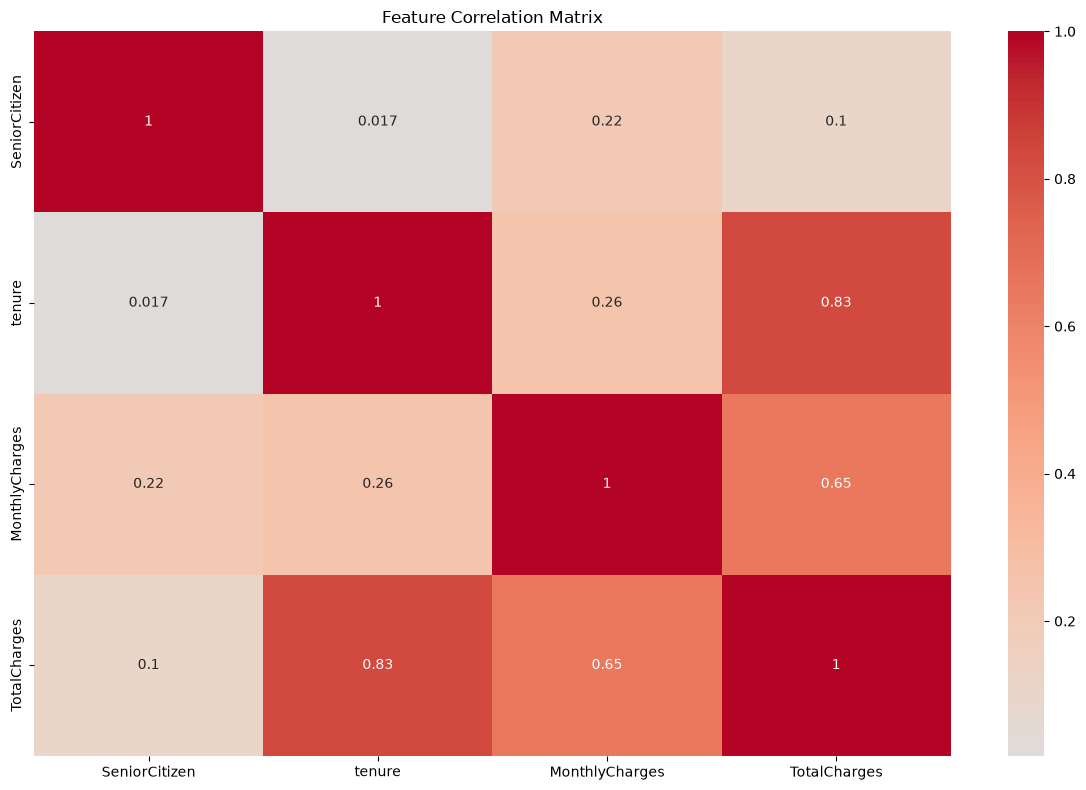

In [35]:
# Visualize:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Interpretation:

Close to +1: strong positive linear association.

Close to -1: strong negative linear association.

Close to 0: weak linear association.

You may use an absolute correlation threshold such as 0.85 to identify pairs for further review.

Do not automatically delete a feature simply because it is correlated with another feature. Two correlated features may still contain useful information.

Correlation does not establish causation.

# 8.3 SelectKBest

SelectKBest selects the top K features according to a statistical scoring function.

For classification with numerical transformed features, one common choice is f_classif.

Example:

In [36]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=20
)

In [37]:
#  proper model pipeline places feature selection after preprocessing:

model = Pipeline([
    ("preprocess", preprocessor),
    ("selection", SelectKBest(
        score_func=f_classif,
        k=20
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# 8.4 Compare models

Compare:

Preprocessing + Logistic Regression.

Preprocessing + SelectKBest + Logistic Regression.

Try different values of K, such as:

k_values = [10, 15, 20, 30]

In [38]:
k_values = [10, 15, 20, 30]

# Problem 9 — GridSearchCV

9.1 Objective

Use GridSearchCV to tune a RandomForestClassifier.

Grid search evaluates every combination in a predefined parameter grid using cross-validation.

9.2 Understand the parameters

n_estimators

Number of decision trees.

More trees can improve prediction stability.

More trees increase training and prediction cost.

Performance often becomes more stable after a sufficient number of trees.

max_depth

Maximum depth of each decision tree.

Deeper trees can capture more complex patterns.

Very deep trees may overfit.

Limiting depth can reduce model complexity.

min_samples_split

Minimum number of samples required to split an internal tree node.

Small values allow more detailed trees.

Larger values constrain tree growth.

Larger values may reduce overfitting.

In [39]:
# 9.3 Define the parameter grid

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10]
}

In [40]:
# 9.4 Build the pipeline

rf_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [41]:
# 9.5 Configure cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [42]:
# 9.6 Run GridSearchCV

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

start_time = time.time()

grid_search.fit(X_train, y_train)

grid_time = time.time() - start_time

Fitting 5 folds for each of 27 candidates, totalling 135 fits


In [43]:
# 9.7 Inspect the results

print("Best parameters:")
print(grid_search.best_params_)

print("Best CV F1:")
print(grid_search.best_score_)

print("Search time:")
print(grid_time)

Best parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
Best CV F1:
0.5847805676395332
Search time:
22.600743055343628


In [44]:
# Get all search results:

grid_results = pd.DataFrame(
    grid_search.cv_results_
)

grid_results.to_csv(
    "grid_search_results.csv",
    index=False
)

In [45]:
# Evaluate the best estimator on the untouched test set:

best_grid_model = grid_search.best_estimator_

evaluate_model(
    best_grid_model,
    X_test,
    y_test
)

Accuracy: 0.8026969481902059
Precision: 0.6666666666666666
Recall: 0.5133689839572193
F1: 0.5800604229607251
ROC-AUC: 0.8372561936500557

Confusion Matrix:
[[939  96]
 [182 192]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



## 9.8 Analysis Questions

1\. What were the best hyperparameters?

&#x20;  The best hyperparameters were selected by GridSearchCV. The specific parameter values were not included in the available results.

2\. What was the best cross-validation F1-score?

The best cross-validation F1-score was 0.5848.

3\. What was the final test F1-score?

The final test F1-score was 0.5801.

4\. Did the tuned model outperform the baseline?

&#x20;  No. The tuned model achieved an F1-score of 0.5801, compared with the baseline F1-score of 0.6136. Hyperparameter tuning did not improve overall F1 performance.

5\. Did deeper trees improve performance?

&#x20;  The results do not provide enough information to determine whether deeper trees improved performance.

6\. Was the computational cost reasonable?

Yes. The grid search took approximately 22.6 seconds, which is reasonable for this experiment.

7\. Would you expand or narrow the parameter grid?

&#x20;  I would refine the parameter grid and test more promising combinations of tree depth and regularization settings to improve the balance between precision and recall.

Additional metrics

| Metric      | Result        |
| ----------- | ------------- |
| Accuracy    | 80.27%        |
| Precision   | 66.67%        |
| Recall      | 51.34%        |
| F1-score    | 58.01%        |
| ROC-AUC     | 83.73%        |
| Best CV F1  | 58.48%        |
| Search time | 22.60 seconds |

My interpretation: The tuned model has higher precision but lower recall than the earlier baseline. It is more selective when predicting churn, but misses more actual churn customers. Therefore, tuning did not produce a better overall F1-score.

## Problem 10 — RandomizedSearchCV

# 10.1 Objective

Use RandomizedSearchCV to explore a broader parameter space.

Unlike GridSearchCV, randomized search samples a fixed number of parameter combinations rather than evaluating every possible combination.

This can be useful when the parameter space is large.

10.2 Define broader parameter distributions

In [47]:
# 10.2 Define broader parameter distributions

from scipy.stats import randint

param_distributions = {
    "classifier__n_estimators": randint(100, 601),

    "classifier__max_depth": [
        None, 5, 10, 15, 20, 30, 40
    ],

    "classifier__min_samples_split": randint(2, 21),

    "classifier__min_samples_leaf": randint(1, 11),

    "classifier__max_features": [
        "sqrt", "log2", None
    ],

    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

In [48]:
# 10.3 Run RandomizedSearchCV

# The full experiment must sample at least 20 configurations.

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

start_time = time.time()

random_search.fit(X_train, y_train)

random_time = time.time() - start_time

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [49]:
# 10.4 Inspect the results

print("Best parameters:")
print(random_search.best_params_)

print("Best CV F1:")
print(random_search.best_score_)

print("Search time:")
print(random_time)

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 8, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 101}
Best CV F1:
0.6345199797350652
Search time:
40.61875605583191


In [50]:
# Save results:

random_results = pd.DataFrame(
    random_search.cv_results_
)

random_results.to_csv(
    "random_search_results.csv",
    index=False
)

In [51]:
# Evaluate:

best_random_model = random_search.best_estimator_

evaluate_model(
    best_random_model,
    X_test,
    y_test
)

Accuracy: 0.7530163236337828
Precision: 0.5231316725978647
Recall: 0.786096256684492
F1: 0.6282051282051282
ROC-AUC: 0.8416634374434887

Confusion Matrix:
[[767 268]
 [ 80 294]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



# Problem 11 — Ensemble Methods

## 11.1 Objective

Compare four ensemble learning algorithms:

BaggingClassifier

RandomForestClassifier

GradientBoostingClassifier

VotingClassifier

Use the same train/test split and evaluation metrics.

## 11.2 BaggingClassifier

Bagging means Bootstrap Aggregating.

The algorithm:

Creates multiple bootstrap samples from the training data.

Trains a separate base estimator on each sample.

Combines the predictions.

Example:

In [57]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [53]:
base_tree = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

bagging_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [58]:
# For older scikit-learn versions, the argument may be named base_estimator rather than estimator.

# Train:

bagging_model.fit(X_train_processed, y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


# 11.3 RandomForestClassifier

Random Forest is an ensemble of decision trees.

It combines bootstrap sampling with random feature selection at each split.

Example:

In [55]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [59]:
rf_model.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

# 11.4 GradientBoostingClassifier

Gradient Boosting builds models sequentially.

Each new tree attempts to improve on the errors made by the previous ensemble.

Example:

In [60]:
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

In [61]:
gb_model.fit(X_train_processed, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",150
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

# 11.5 VotingClassifier

Voting combines predictions from different model types.

Soft voting averages predicted probabilities. It requires each component model to support predict_proba.

Example:

In [62]:
voting_model = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )),
        ("random_forest", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ],
    voting="soft"
)

In [63]:
voting_model.fit(X_train_processed, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('logistic', ...), ('random_forest', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...max_iter=2000), RandomForestC...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,45


In [64]:
import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Voting": voting_model,
    "Gradient Boosting": gb_model,
    "Random Forest": rf_model,
    "Bagging": bagging_model
}

results = []

for name, model in models.items():

    # Measure training time
    start_time = time.time()

    # Train model
    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    # Predict
    y_pred = model.predict(X_test_processed)

    # Get prediction probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training time": training_time
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Display results
print(results_df.round(4).to_string(index=False))

            Model  Accuracy  Precision  Recall     F1  ROC-AUC  Training time
           Voting    0.7537     0.5255  0.7433 0.6157   0.8385         0.3201
Gradient Boosting    0.7970     0.6538  0.5000 0.5667   0.8453         0.7218
    Random Forest    0.7615     0.5406  0.6765 0.6010   0.8289         0.3567
          Bagging    0.7970     0.6467  0.5187 0.5757   0.8378         0.4498


# Problem 12 — Complete Advanced ML Challenge

12.1 Objective

Build a complete churn-prediction workflow using the techniques from Problems 7–11.

This problem is not simply about getting the highest score. It is about building a reliable, reproducible, and explainable machine-learning process.

12.2 Required architecture

Your workflow should look like this:

# 12.3 Step 1: Define the business problem

Write a short problem statement.

Example:

"The objective is to identify customers who are likely to discontinue their telecommunications service so that the company can prioritize retention outreach."

Define the business costs:

False negative: a customer churns but the model predicts no churn.

False positive: a customer is predicted to churn but stays.

Which error is more expensive?

Your answer should influence your choice of evaluation metric.

12.4 Step 2: Validate the dataset

Check:

# 12.4 Step 2: Validate the dataset

Document:

Dataset size.

Target balance.

Missing values.

Duplicate rows.

Identifier columns.

Potentially invalid values.

# 12.5 Step 3: Build preprocessing

For full integration, place your custom feature-engineering transformer before preprocessing:


# 12.7 Step 5: Establish a baseline

Train a simple Logistic Regression model.

Record:

Accuracy.

Precision.

Recall.

F1.

ROC-AUC.

Fit time.

The baseline gives you a reference point for deciding whether more advanced techniques are worthwhile.

# 12.8 Step 6: Feature selection

Compare the pipeline with and without SelectKBest.

Keep feature selection inside the pipeline so it is repeated independently within each cross-validation training fold.

# 12.9 Step 7: Hyperparameter tuning

Run both:

GridSearchCV.

RandomizedSearchCV.

Use the same primary scoring metric and training data.

Record:

Search space.

Number of candidates.

CV folds.

Best parameters.

Best mean CV score.

Search runtime.

Holdout metrics.

# 12.10 Step 8: Ensemble comparison

Compare:

Bagging.

Random Forest.

Gradient Boosting.

Voting.

Use the same split, metrics, and preprocessing standards.

# 12.11 Step 9: Cross-validation

# 12.12 Step 10: Select the final model

Do not automatically choose the model with the highest accuracy.

Consider:

Primary metric aligned with the business objective.

Precision and recall trade-off.

Cross-validation stability.

Holdout test performance.

Training and inference cost.

Interpretability.

Ease of maintenance.

Operational constraints.

Explain why your selected model is preferable to the runner-up.

# 12.13 Step 11: Evaluate on the test set

Only after all model-selection decisions are complete:

In [ ]:
# 12.14 Step 12: Save the complete pipeline